# Assignment 2 — AIMLZG565 — Machine Learning

**WILP Division**
**M. Tech. in Artificial Intelligence & Machine Learning**
**I Semester 2026-27**

---

**Assignment I**

**Student Name:** RAHUL GUPTA
**BITS ID:** 2026AJ05022
**Semester:** 1st (2026-27)

---

## Multi Model Classification and App Deployment

### Problem statement
In this assignment, we have to implement the following:
- Implement multiple classification models
- Build an interactive Streamlit web application to demonstrate your models
- Deploy the app on Streamlit Community Cloud (FREE)
---

## Dataset Used
Heart Disease Prediction Dataset 2026

https://www.kaggle.com/datasets/mohankrishnathalla/heart-disease-prediction-dataset-2026


In [ ]:
import warnings, time, sys, os, urllib.request
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

np.random.seed(12)

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "figure.autolayout": True, "axes.titleweight": "bold"})

In [ ]:
"""#Saving the models

# 1. Create dummy data and train a model
X, y = make_classification(n_samples=100, n_features=4)
model = RandomForestClassifier()
model.fit(X, y)

# 2. Save the trained model to a file
# Pass the model object and your desired file path
joblib.dump(model, 'my_trained_model.joblib')
print("Model saved successfully!")

# 3. Load the model back at a later time
loaded_model = joblib.load('my_trained_model.joblib')

# 4. Use the loaded model to make predictions
predictions = loaded_model.predict(X)"""

## 1. Loading the data

In [ ]:
# The three files are read from the working directory (or ./data). If they are not present the
# notebook downloads them from the Google-Drive links given in the assignment brief.
FILES = {
    "bike_train.csv":       "18kpPgnoDfOfx3PRRZY3xbsLeWalNViYl",
    "bike_test.csv":        "1HJlgPTkGlCzycSTnJNB0oJEfgjSV4o0f",
    "sampleSubmission.csv": "1g_hQQtI80Dz0NkGXG8ZioND9iVGTerd8",
}
SEARCH_DIRS = [".", "data", "./data", "../data", "/content", "/content/data"]


def locate(fname, file_id):
    for d in SEARCH_DIRS:
        p = os.path.join(d, fname)
        if os.path.exists(p):
            return p
    os.makedirs("data", exist_ok=True)
    p = os.path.join("data", fname)
    url = f"https://drive.usercontent.google.com/download?id={file_id}&export=download"
    print(f"downloading {fname} ...")
    urllib.request.urlretrieve(url, p)
    return p


paths = {f: locate(f, i) for f, i in FILES.items()}
train  = pd.read_csv(paths["bike_train.csv"])
test   = pd.read_csv(paths["bike_test.csv"])
sample = pd.read_csv(paths["sampleSubmission.csv"])

for name, df in [("bike_train", train), ("bike_test", test), ("sampleSubmission", sample)]:
    print(f"Dataset: {name:18s} \nShape: {str(df.shape):12s} \nColoumns: {list(df.columns)}\n\n")

Dataset: bike_train         
Shape: (10450, 12)  
Coloumns: ['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']


Dataset: bike_test          
Shape: (2613, 9)    
Coloumns: ['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed']


Dataset: sampleSubmission   
Shape: (2613, 2)    
Coloumns: ['datetime', 'Count_Predicted']




In [ ]:
# ------ Printing first 5 rows of the datasets to view the columns and entry type ------
print("irst 5 Rows of Training Dataset:")
display(train.head())
print("\n\nFirst 5 Rows of Test Dataset:")
display(test.head())
print("\n\nFirst 5 Rows of Submission Dataset:")
display(sample.head())

irst 5 Rows of Training Dataset:


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2012-07-15 7:00:00,3,0,0,1,28.70000,33.335000,79,6.003200,17,30,47
1,2012-08-14 15:00:00,3,0,1,1,33.62000,37.880000,46,15.001300,84,199,283
2,2011-02-06 6:00:00,1,0,0,1,10.66000,12.880000,60,15.001300,0,1,1
3,2012-05-06 17:00:02,2,0,0,2,26.42506,30.566166,61,9.512288,198,330,531
4,2012-01-09 2:00:00,1,0,1,1,9.84000,12.120000,56,8.998100,2,3,5




First 5 Rows of Test Dataset:


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed
0,05-06-2012 5:00,2,0,1,3,19.680000,23.48500,82,11.00140
1,19-03-2011 19:00,1,0,0,1,18.040000,21.97000,33,19.00120
2,02-04-2012 6:00,2,0,1,1,13.885038,16.24664,68,29.52646
3,13-07-2012 20:00,3,0,1,1,30.340000,33.33500,48,8.99810
4,09-11-2011 19:00,4,0,1,1,18.040000,21.97000,72,7.00150




First 5 Rows of Submission Dataset:


,datetime,Count_Predicted
0,05-06-2012 5:00,NaN
1,19-03-2011 19:00,NaN
2,02-04-2012 6:00,NaN
3,13-07-2012 20:00,NaN
4,09-11-2011 19:00,NaN


In [ ]:
# ------ Standardizing the Timestamps across the Training and Test sets by adding another coloumn 'dt' ------
print("Train datetime samples:", train.datetime.head(3).tolist())
print("Test  datetime samples:", test.datetime.head(3).tolist())

train['dt'] = pd.to_datetime(train['datetime'], format='mixed')
test['dt'] = pd.to_datetime(test['datetime'], format='mixed')

print("Train datetime samples after normalisation:", train['dt'].head(3).tolist())
print("Test  datetime samples after normalisation:", test['dt'].head(3).tolist())

Train datetime samples: ['2012-07-15 7:00:00', '2012-08-14 15:00:00', '2011-02-06 6:00:00']
Test  datetime samples: ['05-06-2012 5:00', '19-03-2011 19:00', '02-04-2012 6:00']
Train datetime samples after normalisation: [Timestamp('2012-07-15 07:00:00'), Timestamp('2012-08-14 15:00:00'), Timestamp('2011-02-06 06:00:00')]
Test  datetime samples after normalisation: [Timestamp('2012-05-06 05:00:00'), Timestamp('2011-03-19 19:00:00'), Timestamp('2012-02-04 06:00:00')]


## Q1. Examine dataset size, missing values, and feature types

In [ ]:
print(f"Training set : {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Test set     : {test.shape[0]:,} rows x {test.shape[1]} columns")
print(f"Total        : {train.shape[0] + test.shape[0]:,} rows")
print("\n\nInformation about the Current Training dataset:")
train.info()

# ---- Information about missing values in the datasets ----
print("\n\nMissing values in train:", int(train.isna().sum().sum()))
print("Missing values in test :", int(test.isna().sum().sum()))
print("Fully duplicated rows in train:", int(train.duplicated().sum()))

# ---- Numeric analysis of the Target variable ----
y_full = train["count"].values
print("\n\nNumeric analysis of the Target variable:")
display(train["count"].describe().to_frame().T)
print(f"skewness of count        : {train['count'].skew():.3f}")
print(f"skewness of log1p(count) : {np.log1p(train['count']).skew():.3f}")

# ---- Information about the continous variables in the Train dataset ----
print("\n\nInformation about the continous variables in the Current Training dataset:")
display(train[["temp", "atemp", "humidity", "windspeed"]].describe().T)

# ---- Checking balance of the categorical variables in the dataset ----
print("\n\nChecking balance of the categorical variables in the dataset:")
for c in ["season", "holiday", "workingday", "weather"]:
    vc = train[c].value_counts().sort_index()
    print(f"{c:12s}", " | ".join(f"{k}:{v}" for k, v in vc.items()))

Training set : 10,450 rows x 13 columns
Test set     : 2,613 rows x 10 columns
Total        : 13,063 rows


Information about the Current Training dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10450 entries, 0 to 10449
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10450 non-null  object        
 1   season      10450 non-null  int64         
 2   holiday     10450 non-null  int64         
 3   workingday  10450 non-null  int64         
 4   weather     10450 non-null  int64         
 5   temp        10450 non-null  float64       
 6   atemp       10450 non-null  float64       
 7   humidity    10450 non-null  int64         
 8   windspeed   10450 non-null  float64       
 9   casual      10450 non-null  int64         
 10  registered  10450 non-null  int64         
 11  count       10450 non-null  int64         
 12  dt          10450 non-null  datetime64[ns]
dtypes: datetim

,count,mean,std,min,25%,50%,75%,max
count,10450.0,190.410526,181.038755,1.0,42.0,143.0,283.0,977.0


skewness of count        : 1.260
skewness of log1p(count) : -0.897


Information about the continous variables in the Current Training dataset:


,count,mean,std,min,25%,50%,75%,max
temp,10450.0,20.191700,7.792683,0.82,13.9400,20.50000,26.2400,41.0000
atemp,10450.0,23.605793,8.478045,0.76,16.6650,24.24000,31.0600,45.4550
humidity,10450.0,61.924211,19.245193,0.00,47.0000,62.00000,77.0000,100.0000
windspeed,10450.0,12.765259,8.102821,0.00,7.0015,12.45005,16.9979,56.9969




Checking balance of the categorical variables in the dataset:
season       1:2582 | 2:2608 | 3:2630 | 4:2630
holiday      0:10149 | 1:301
workingday   0:3389 | 1:7061
weather      1:6945 | 2:2686 | 3:818 | 4:1


**Analysis of Training and Test datasets**

1. **Siz:** The training set has **10,450 rows x 12 columns** and the test set **2,613 rows x 9 columns**
(13,063 rows in total). The target is `count`; `bike_test.csv` legitimately lacks `count`, and also
lacks `casual` and `registered`.

2. **Missing values:** There are **no `NaN` values anywhere** in either file, and no fully duplicated
rows.

3. **Format:** The `datetime` column is formatted differently in the two files — `bike_train.csv` uses
   `YYYY-MM-DD H:MM:SS`, `bike_test.csv` uses `DD-MM-YYYY H:MM`. Each therefore needs its own
   explicit parse format; hence, a new coloumn with the comman format `dt` was created.

4. **Class Balance:** `season` is almost perfectly balanced (2,582–2,630
per level), but `weather` is severely imbalanced — 6,945 / 2,686 / 818 and a **single** level-4
observation, so no reliable effect can be estimated for heavy rain/snow.

5. **Feature Reduction:** `casual` and `registered` must be dropped. They are the two components of the target and their
   sum correlates with `count` at **ρ = 0.9987**, so using them as predictors would be target leakage
   — and in any case neither column exists in `bike_test.csv`.


## Q2. Visualize relationships between key features and count

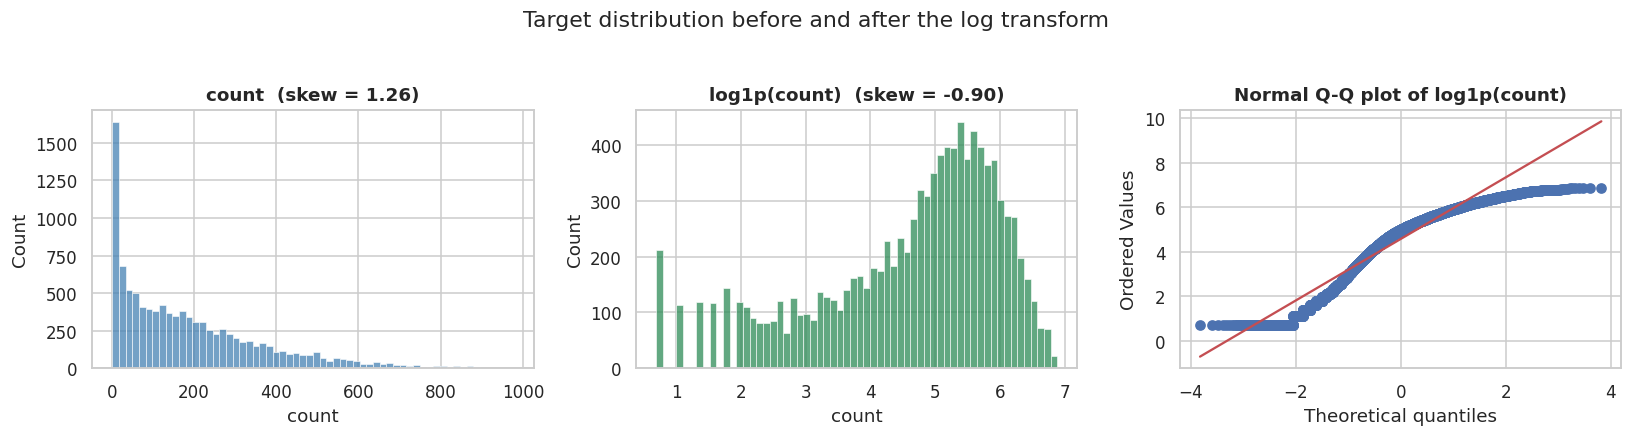

In [ ]:
# ---- Checking the distribution of the Target (count) in the dataset ----
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(train["count"], bins=60, ax=ax[0], color="steelblue")
ax[0].set_title(f"count  (skew = {train['count'].skew():.2f})")
sns.histplot(np.log1p(train["count"]), bins=60, ax=ax[1], color="seagreen")
ax[1].set_title(f"log1p(count)  (skew = {np.log1p(train['count']).skew():.2f})")
from scipy import stats
stats.probplot(np.log1p(train["count"]), dist="norm", plot=ax[2])
ax[2].set_title("Normal Q-Q plot of log1p(count)")
plt.suptitle("Target distribution before and after the log transform", y=1.04)
plt.show()

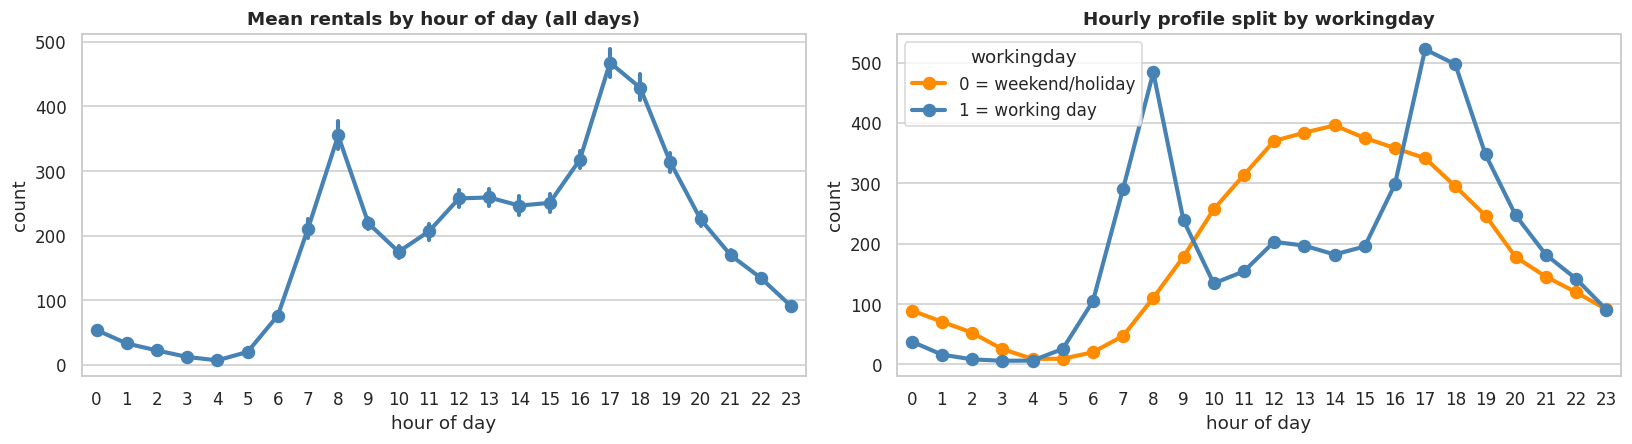

In [ ]:
# ---- Checking the effect of Hour and Workingday on the Target (count) in the dataset ----
eda = train.copy()
eda["hour"]    = train['dt'].dt.hour
eda["weekday"] = train['dt'].dt.dayofweek           # 0 = Monday
eda["month"]   = train['dt'].dt.month
eda["year"]    = train['dt'].dt.year
eda["date"]    = train['dt'].dt.date

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
sns.pointplot(data=eda, x="hour", y="count", errorbar=("ci", 95), ax=ax[0], color="steelblue")
ax[0].set_title("Mean rentals by hour of day (all days)")
sns.pointplot(data=eda, x="hour", y="count", hue="workingday", errorbar=None, ax=ax[1],
              palette={0: "darkorange", 1: "steelblue"})
ax[1].set_title("Hourly profile split by workingday")
ax[1].legend(title="workingday", labels=["0 = weekend/holiday", "1 = working day"])
for a in ax:
    a.set_xlabel("hour of day"); a.set_ylabel("count")
plt.show()

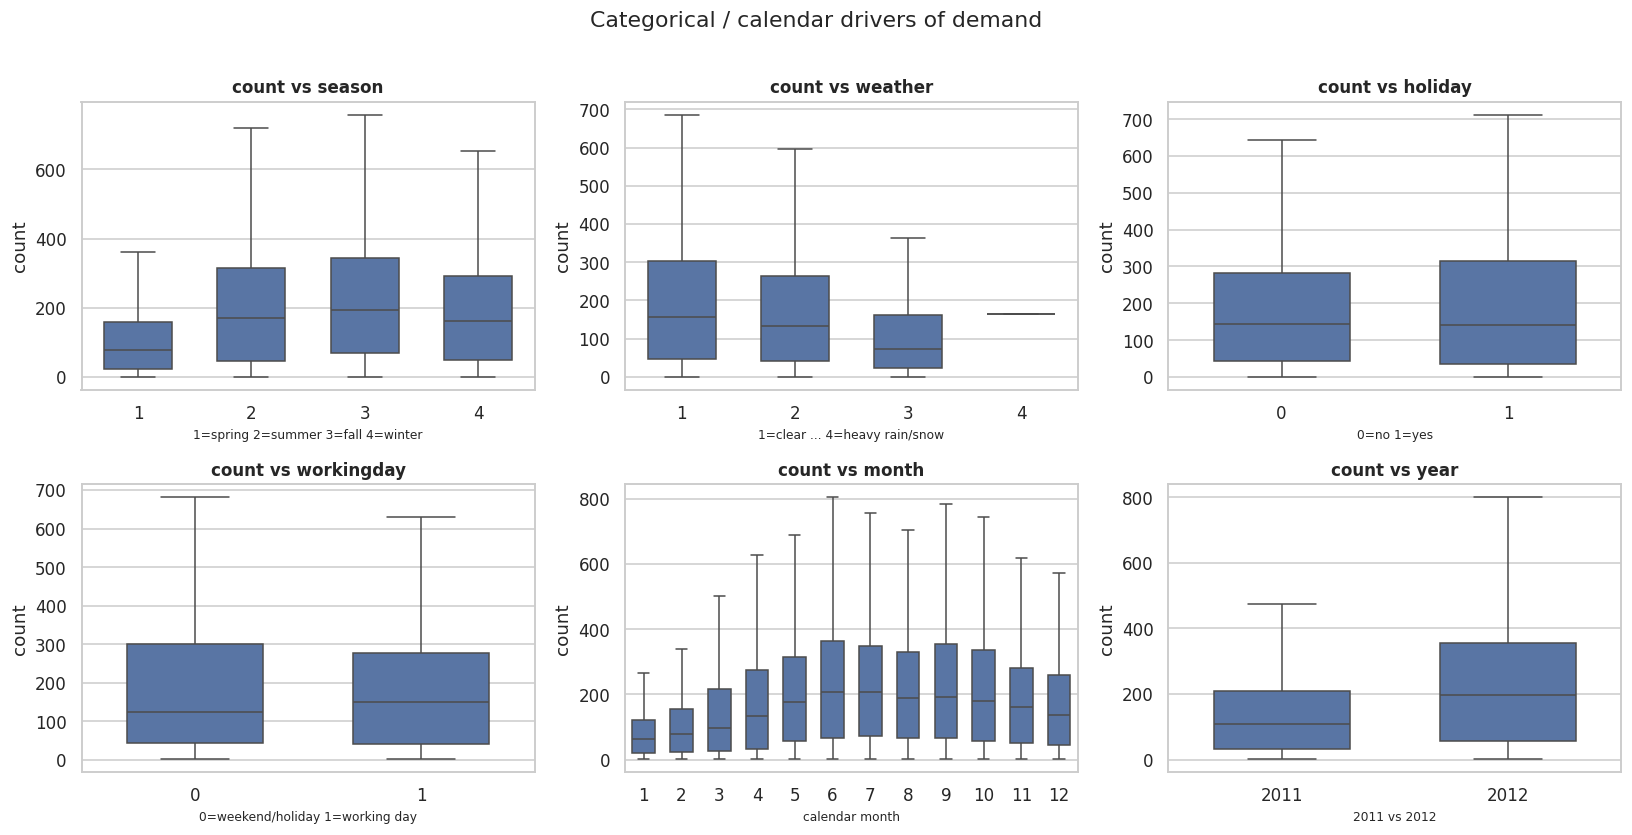

In [ ]:
# ---- Checking the effect of Categorical Features on the Target (count) in the dataset ----
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
specs = [("season",     "1=spring 2=summer 3=fall 4=winter"),
         ("weather",    "1=clear ... 4=heavy rain/snow"),
         ("holiday",    "0=no 1=yes"),
         ("workingday", "0=weekend/holiday 1=working day"),
         ("month",      "calendar month"),
         ("year",       "2011 vs 2012")]
for a, (col, sub) in zip(ax.ravel(), specs):
    sns.boxplot(data=eda, x=col, y="count", ax=a, showfliers=False, width=.6)
    a.set_title(f"count vs {col}", fontsize=11)
    a.set_xlabel(sub, fontsize=8); a.set_ylabel("count")
plt.suptitle("Categorical / calendar drivers of demand", y=1.01)
plt.show()

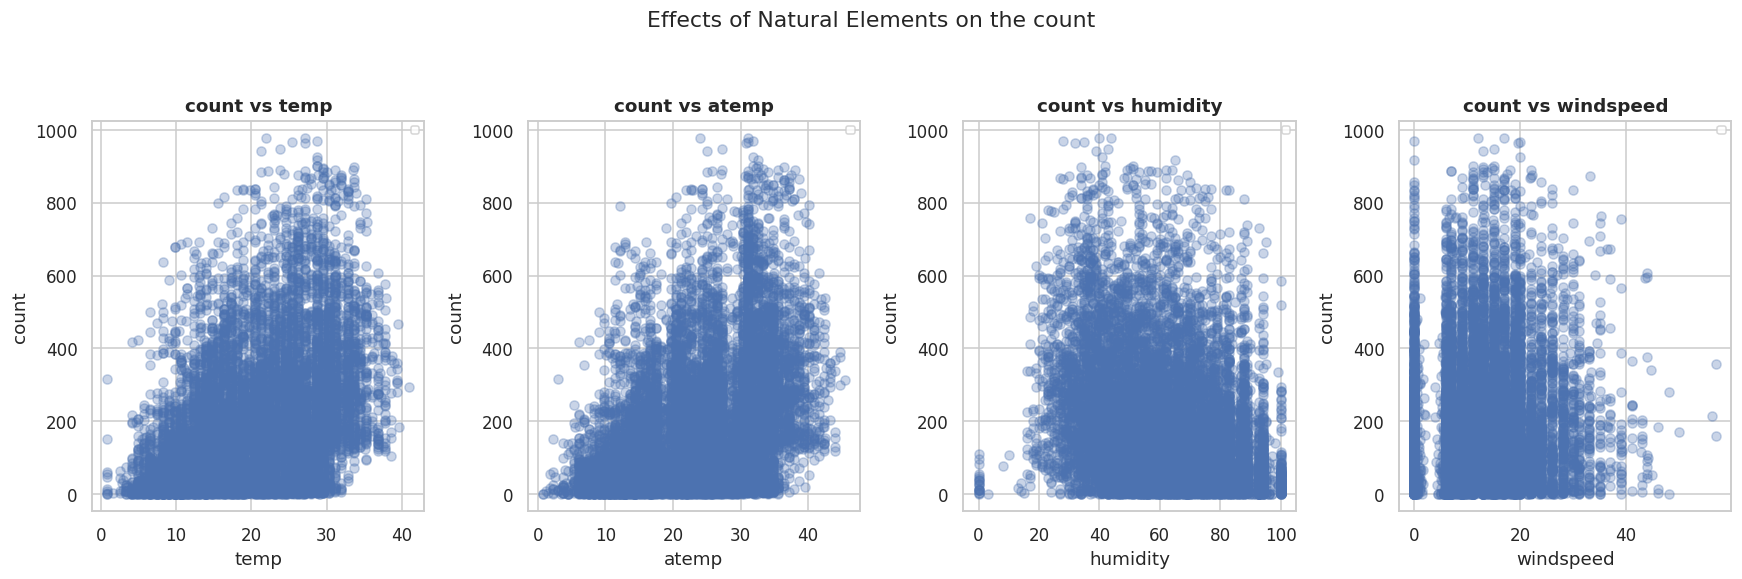

In [ ]:
# ---- Checking the effect of Elemenatal Features on the Target (count) in the dataset ----
fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for a, col in zip(ax, ["temp", "atemp", "humidity", "windspeed"]):
    a.scatter(train[col], train['count'], alpha=0.3)
    a.set_title(f"count vs {col}")
    a.set_xlabel(col); a.set_ylabel("count"); a.legend(fontsize=7)
plt.suptitle("Effects of Natural Elements on the count", y=1.05)
plt.show()

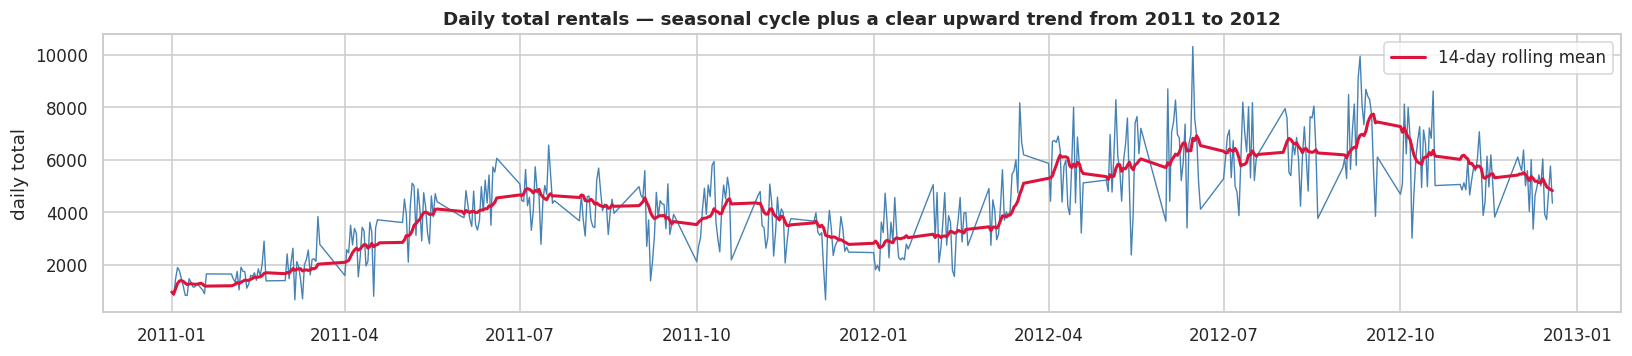

In [ ]:
# ---- Checking the trend of the Daily Target (count) ----
daily = eda.groupby("date")["count"].sum()
plt.figure(figsize=(15, 3.4))
plt.plot(pd.to_datetime(daily.index), daily.values, lw=.9, color="steelblue")
plt.plot(pd.to_datetime(daily.index), daily.rolling(14, min_periods=1).mean().values,
         lw=2, color="crimson", label="14-day rolling mean")
plt.title("Daily total rentals — seasonal cycle plus a clear upward trend from 2011 to 2012")
plt.ylabel("daily total"); plt.legend()
plt.show()

**Analysis of Graphs Generated:**

1. **Time-of-day (`hour`) is by far the dominant driver, and its effect is conditional on `workingday`.**
On working days demand is bimodal with commuter spikes at **08:00** and
**17:00–18:00**, and the least at **03:00–04:00**. On weekends and holidays the same variable produces a completely different,
single-humped leisure profile peaking around **13:00–15:00** with a much shallower night
trough (≈ 9).

2. **Weather effects are real but secondary, and non-linear.** `temp`/`atemp` rise with demand up to
roughly 30–33 °C and then plateau or decline — a quadratic shape, not a straight line. `humidity` is
monotonically negative. `weather` severity is strongly ordered: mean count falls from
**203.8** (clear, 6,945 rows) to **176.5** (mist, 2,686) to **122.4** (light rain/snow, 818), with a
**single** level-4 observation from which nothing can be estimated. `windspeed` is weak and noisy.

3. **There is a strong seasonal cycle and a year-over-year growth trend.** Fall/summer months carry
roughly double the demand of January–February, and 2012 averages **237.1** rentals/hour against
**143.6** in 2011.

4. **`holiday` is almost uninformative on its own** as its boxplot
largely overlaps the non-holiday one; the information it carries is already contained in `workingday`.

5. Finally, `temp` and `atemp` are almost perfectly collinear. Both are retained because
Ridge handles collinearity gracefully, but neither coefficient can be interpreted individually.

## Q3. Which variables are likely to be most informative?

In [ ]:
# ---- Checking the correlation of the Numeic Features w.r.t to the Target (count) in the dataset ----

numeric_cols = train.select_dtypes(include='number')

correlation = numeric_cols.corr()['count'].sort_values(ascending=False)

print(correlation)

count         1.000000
registered    0.970108
casual        0.691971
temp          0.396451
atemp         0.390642
season        0.160333
windspeed     0.105318
workingday    0.017361
holiday      -0.005615
weather      -0.124402
humidity     -0.316607
Name: count, dtype: float64


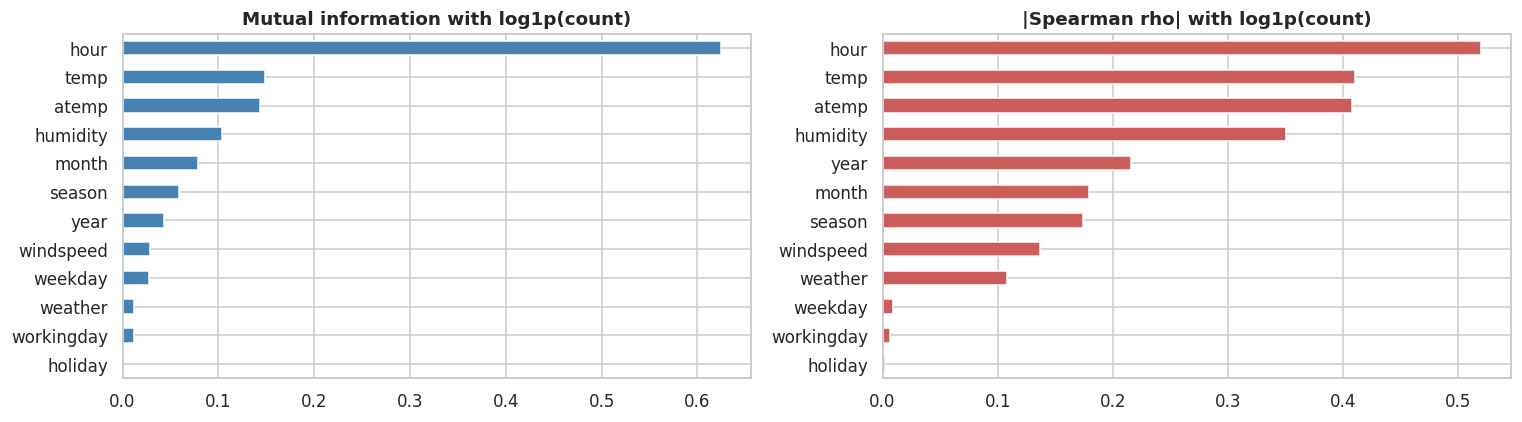

,mutual_information,abs_spearman
hour,0.625,0.520
temp,0.149,0.410
atemp,0.143,0.408
humidity,0.104,0.350
month,0.079,0.179
season,0.059,0.174
year,0.043,0.216
windspeed,0.029,0.137
weekday,0.028,0.009
weather,0.012,0.108


In [ ]:
# ---- Checking the Mutual Information Gain w.r.t to the Target (count) in the dataset ----
mi_frame = eda[["hour", "weekday", "month", "year", "season", "weather", "holiday",
                "workingday", "temp", "atemp", "humidity", "windspeed"]].copy()
discrete = [c in ("hour", "weekday", "month", "year", "season", "weather", "holiday", "workingday")
            for c in mi_frame.columns]
mi = mutual_info_regression(mi_frame, np.log1p(eda["count"]),
                            discrete_features=discrete, random_state=12)

corr_cols = ["temp", "atemp", "humidity", "windspeed", "season", "weather",
             "holiday", "workingday", "hour", "weekday", "month", "year", "count"]
cm = eda[corr_cols].assign(log1p_count=np.log1p(eda["count"])).corr(method="spearman")

rank = pd.DataFrame({
    "mutual_information": mi,
    "abs_spearman": [abs(cm.loc[c, "log1p_count"]) for c in mi_frame.columns],
}, index=mi_frame.columns).sort_values("mutual_information", ascending=False).round(3)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
rank["mutual_information"].plot.barh(ax=ax[0], color="steelblue")
ax[0].invert_yaxis(); ax[0].set_title("Mutual information with log1p(count)")
rank["abs_spearman"].sort_values().plot.barh(ax=ax[1], color="indianred")
ax[1].set_title("|Spearman rho| with log1p(count)")
plt.show()
display(rank)

**Analysis of Graphs Generated:**

1. **Time-of-day (`hour`) is by far the dominant driver, and its effect is conditional on `workingday`.**
On working days demand is bimodal with commuter spikes at **08:00** and
**17:00–18:00**, and the least at **03:00–04:00**. On weekends and holidays the same variable produces a completely different,
single-humped leisure profile peaking around **13:00–15:00** with a much shallower night
trough (≈ 9).

2. **Weather effects are real but secondary, and non-linear.** `temp`/`atemp` rise with demand up to
roughly 30–33 °C and then plateau or decline — a quadratic shape, not a straight line. `humidity` is
monotonically negative. `weather` severity is strongly ordered: mean count falls from
**203.8** (clear, 6,945 rows) to **176.5** (mist, 2,686) to **122.4** (light rain/snow, 818), with a
**single** level-4 observation from which nothing can be estimated. `windspeed` is weak and noisy.

3. **There is a strong seasonal cycle and a year-over-year growth trend.** Fall/summer months carry
roughly double the demand of January–February, and 2012 averages **237.1** rentals/hour against
**143.6** in 2011.

4. **`holiday` is almost uninformative on its own** as its boxplot
largely overlaps the non-holiday one; the information it carries is already contained in `workingday`.

5. Finally, `temp` and `atemp` are almost perfectly collinear. Both are retained because
Ridge handles collinearity gracefully, but neither coefficient can be interpreted individually.

## Q4. Feature Engineering

In [ ]:
# ---- Defining a function to add more time related features in the dataset ----

def make_features(df):
    x = df.copy()

    dt = x.pop('dt')

    x['year'] = dt.dt.year
    x['month'] = dt.dt.month
    x['day'] = dt.dt.day
    x['hour'] = dt.dt.hour
    x['weekday'] = dt.dt.dayofweek
    x['day_of_ye'] = dt.dt.dayofyear

    x['hour_work'] = (x['hour'].astype(str) + '_' + x['workingday'].astype(str))

    x['hour_weekday'] = (x['hour'].astype(str) + '_' + x['weekday'].astype(str))

    x['year_month'] = (x['year'].astype(str) + '_' + x['month'].astype(str))

    return x

In [ ]:
# ---- Adding more time related features in the dataset ----

X = make_features(train).drop(columns=['datetime', 'count', 'casual', 'registered'])
y = train['count']

print("engineered design frame:", X.shape)
print("\ncolumns:", list(X.columns))

print("\nFirst 5 Rows of the modified Dataset:")
display(X.head())

engineered design frame: (10450, 17)

columns: ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'year', 'month', 'day', 'hour', 'weekday', 'day_of_ye', 'hour_work', 'hour_weekday', 'year_month']

First 5 Rows of the modified Dataset:


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,year,month,day,hour,weekday,day_of_ye,hour_work,hour_weekday,year_month
0,3,0,0,1,28.70000,33.335000,79,6.003200,2012,7,15,7,6,197,7_0,7_6,2012_7
1,3,0,1,1,33.62000,37.880000,46,15.001300,2012,8,14,15,1,227,15_1,15_1,2012_8
2,1,0,0,1,10.66000,12.880000,60,15.001300,2011,2,6,6,6,37,6_0,6_6,2011_2
3,2,0,0,2,26.42506,30.566166,61,9.512288,2012,5,6,17,6,127,17_0,17_6,2012_5
4,1,0,1,1,9.84000,12.120000,56,8.998100,2012,1,9,2,0,9,2_1,2_0,2012_1


**Analysis of the Feature Engineering conducted:**

**1. Calendar decomposition of `datetime`.** `datetime` is an identifier and not helpful as a number.
It is decomposed into `year`, `month`, `day`, `hour`, `weekday`, `day_of_ye`, `hour_work`, `hour_weekday`, and `year_month`.

**2. Target transformation.** All models are fitted on **`log1p(count)`** and predictions are mapped
back with `expm1`. This is the most important single modelling decision, for three reasons:
(i) Minimising squared error on `log1p(y)` *is* minimising RMSLE, so training and evaluation are
aligned;

(ii) It converts the multiplicative structure of demand into an additive one, which is what
a linear model can represent; and

(iii) It removes the right-skew and stabilises the error variance. It also guarantees strictly positive predictions after back-transformation.

**3. Dropped columns which could impact the model.** We removed the coloumns `casual` and `registered` as they did not provide accurate combination to the target. `datetime` was removed as we added a normalized replacement `dt`. The target `count` was removed from the input matrix `X`, and added to a separate target variable, `y`.

## Q5. Data split and Simple Linear Regression

In [ ]:
# ---- Splitting the dataset 80:20 into training and validation sets ----
X_train, X_val, y_train, y_val = train_test_split(X,y,test_size=0.20,random_state=42)
print(f"Shape of the Training Sets: Input {X_train.shape}"," | ", f"Target {y_train.shape}")
print(f"Shape of the Validation Sets: Input {X_val.shape}"," | ", f"Target {y_val.shape}")

Shape of the Training Sets: Input (8360, 17)  |  Target (8360,)
Shape of the Validation Sets: Input (2090, 17)  |  Target (2090,)


In [ ]:
RESULTS = []   # model-comparison registry, printed as a table in Q7
FITTED  = {}   # keep fitted estimators for the residual analysis in Q8

# ---- Function to train and perform predictions with the input model ----
# ---- Function output gets stored in RESULTS and FITTED ----

def register(name, model, features, log_target=True, family="Linear"):
# ---- Fit on the training set, score on the validation set, and record the result. ----
    t0 = time.time()
    mod = clone(model)
    mod.fit(X_train[features], np.log1p(y_train) if log_target else y_train)

    pred_val = mod.predict(X_val[features])
    pred_train = mod.predict(X_train[features])
    if log_target:
        pred_val, pred_train = np.expm1(pred_val), np.expm1(pred_train)
    pred_val, pred_train = np.clip(pred_val, 1, None), np.clip(pred_train, 1, None)

    row = {
        "model": name,
        "family": family,
        "target": "log1p(count)" if log_target else "count",
        "n_features_in": len(features),
        "train_RMSLE": round(rmsle(y_train, pred_train), 4),
        "val_RMSLE": round(rmsle(y_val, pred_val), 4),
        "val_RMSE": round(rmse(y_val, pred_val), 1),
        "time_taken": round(time.time() - t0, 1),
    }
    RESULTS.append(row)
    FITTED[name] = (mod, features, log_target)
    print(f"{name:44s} train={row['train_RMSLE']:.4f}"
          f" val={row['val_RMSLE']:.4f}  "
          f"({row['time_taken']}s)")
    return row["val_RMSLE"]

In [ ]:
# ---- Define the Coloumns/Features to be used in Training ----
raw_cols = [
    'season',
    'holiday',
    'workingday',
    'weather',
    'temp',
    'atemp',
    'humidity',
    'windspeed']

In [ ]:
# ---- M1: the simplest possible model -- raw features, untransformed target ----
m1 = Pipeline([("sc", StandardScaler()), ("lr", LinearRegression())])
register("M1  LinearRegression | raw features, y=count", m1, raw_cols,
         log_target=False)

# ---- M2: identical model, but fitted on log1p(count) ----
register("M2  LinearRegression | raw features, y=log1p", m1, raw_cols,
         log_target=True)

M1  LinearRegression | raw features, y=count train=1.4416 val=1.3951  (0.1s)
M2  LinearRegression | raw features, y=log1p train=1.2485 val=1.2220  (0.2s)


np.float64(1.222)

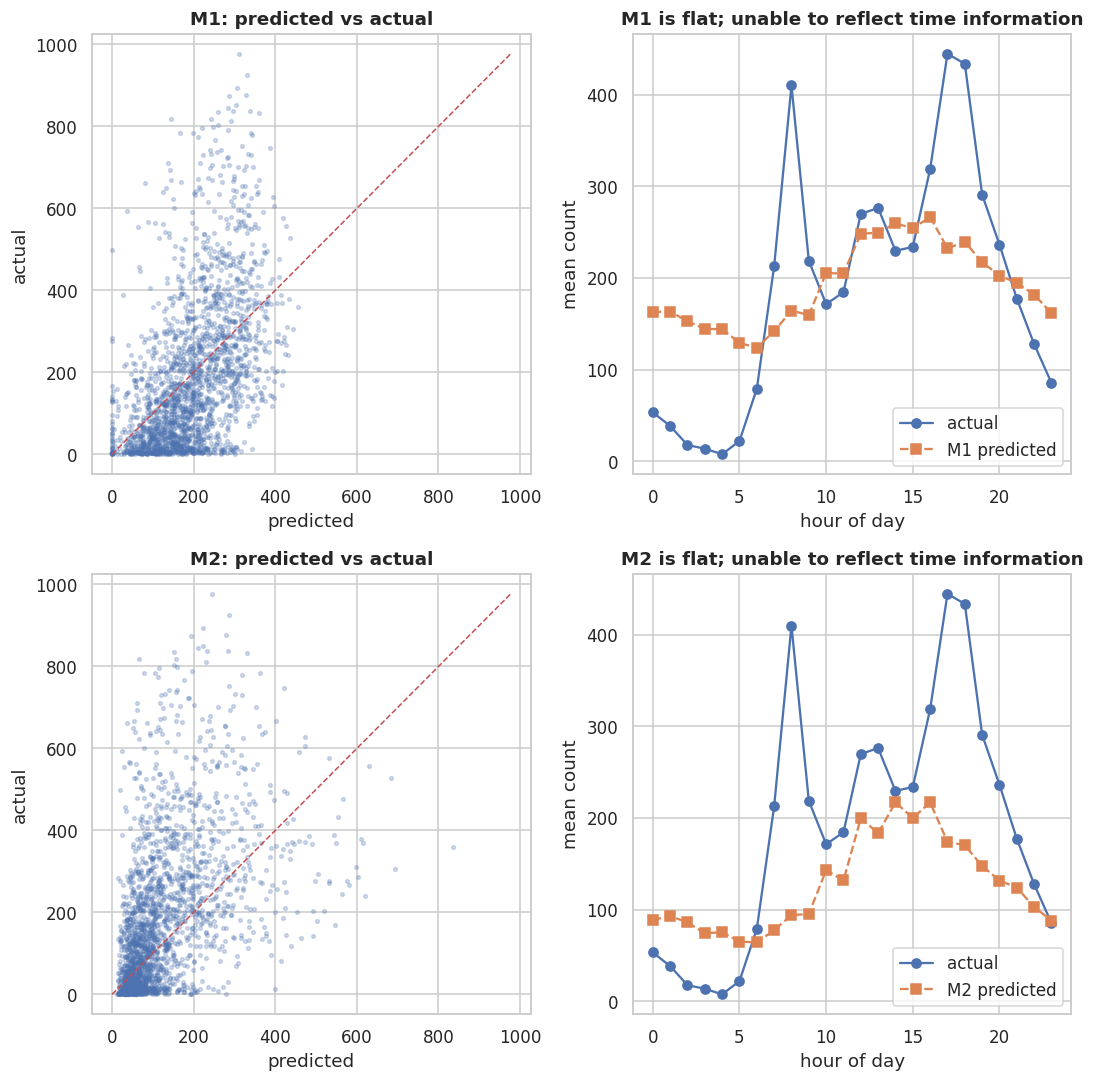

In [ ]:
# ---- Plot the Predictions from the Models M1, and M2 ----
m1_fit, m1_features, _ = FITTED["M1  LinearRegression | raw features, y=count"]
m2_fit, m2_features, _ = FITTED["M2  LinearRegression | raw features, y=log1p"]
pred_val_m1 = np.clip(m1_fit.predict(X_val[m1_features]), 1, None)
pred_val_m2 = np.clip(np.expm1(m2_fit.predict(X_val[m2_features])), 1, None)

fig, ax = plt.subplots(2, 2, figsize=(10, 10))

ax[0,0].scatter(pred_val_m1, y_val, s=6, alpha=.25)
lim = [0, max(y_val.max(), pred_val_m1.max())]
ax[0,0].plot(lim, lim, "r--", lw=1)
ax[0,0].set_xlabel("predicted"); ax[0,0].set_ylabel("actual"); ax[0,0].set_title("M1: predicted vs actual")
tmp = pd.DataFrame({"hour": X_val["hour"].values, "actual": y_val, "pred": pred_val_m1})
h = tmp.groupby("hour")[["actual", "pred"]].mean()
ax[0,1].plot(h.index, h["actual"], "o-", label="actual")
ax[0,1].plot(h.index, h["pred"], "s--", label="M1 predicted")
ax[0,1].set_xlabel("hour of day"); ax[0,1].set_ylabel("mean count"); ax[0,1].legend()
ax[0,1].set_title("M1 is flat; unable to reflect time information")

ax[1,0].scatter(pred_val_m2, y_val, s=6, alpha=.25)
lim = [0, max(y_val.max(), pred_val_m2.max())]
ax[1,0].plot(lim, lim, "r--", lw=1)
ax[1,0].set_xlabel("predicted"); ax[1,0].set_ylabel("actual"); ax[1,0].set_title("M2: predicted vs actual")
tmp = pd.DataFrame({"hour": X_val["hour"].values, "actual": y_val, "pred": pred_val_m2})
h = tmp.groupby("hour")[["actual", "pred"]].mean()
ax[1,1].plot(h.index, h["actual"], "o-", label="actual")
ax[1,1].plot(h.index, h["pred"], "s--", label="M2 predicted")
ax[1,1].set_xlabel("hour of day"); ax[1,1].set_ylabel("mean count"); ax[1,1].legend()
ax[1,1].set_title("M2 is flat; unable to reflect time information")

plt.tight_layout()
plt.show()

**Analysis of the Linear Regression Models:**

**Split.** An 80/20 split produced with `train_test_split` giving the sets with shapes as follows -

Training: Input (8360, 17)  |  Target (8360,)

Validation: Input (2090, 17)  |  Target (2090,)

**Baseline results.**


| Model | Train RMSLE | Validation RMSLE |
|---|---|---|
| M1 — `LinearRegression` & Raw features, target = `count` | 1.4416 | **1.3951** |
| M2 — `LinearRegression` & Raw features, target = `log1p(count)` | 1.2485 | **1.2220** |


**Interpretation.**

* Both models are very poor, and for a structural reason: the raw feature set contains **no time
  information whatsoever**. `datetime` is a string identifier and cannot enter a regression, so the
  model is left with weather and calendar-category variables only. By seeing the Right Plots, both M1 and M2 cannot identify the increase in number of rentals caused by the `hour` of the day.
* **The log transform produces 12 % improvement (1.3951 → 1.2220) with no change to the
  features.** Fitting least squares on `log1p(y)` helps to minimise the RMSLE objective.
* **Inference from Final accuracy**. The model is *under-fitting* as both the `Train RMSLE` & `Validation RMSLE` are bad. This shows the model is rigid to learn the given features properly.


This baseline is the reference point for Q6, where the deficiency is addressed on two fronts —
**engineering the missing time features**, and then **expanding the feature space non-linearly**. All models will use the log transformation for the prediction.

## Q6. Polynomial, Ridge and Lasso Regression

In [ ]:
cat_cols = [
    'season',
    'holiday',
    'workingday',
    'weather',
    'year',
    'month',
    'weekday',
    'hour',
    'hour_work',
    'hour_weekday',
    'year_month'
]

num_cols = [
    'temp',
    'atemp',
    'humidity',
    'windspeed',
    'day',
    'day_of_ye'
]

all_cols = num_cols + cat_cols

In [ ]:
def make_pipeline(estimator, num_features, cat_features, degree=None, interaction_only=False):
    """
    Preprocessing + estimator.

    Numeric block  -> standardise, then (optionally) PolynomialFeatures of the given degree.
    Categorical    -> one-hot, drop='first' to avoid the dummy-variable trap.
    A second StandardScaler after assembly puts every column on a comparable scale, which is what
    makes a single penalty alpha meaningful across the whole design matrix in Ridge/Lasso.
    """
    num_steps = [("scale", StandardScaler())]
    if degree:
        num_steps.append(("poly", PolynomialFeatures(degree, include_bias=False,
                                                     interaction_only=interaction_only)))
    pre = ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), cat_features)])
    return Pipeline([("pre", pre), ("scale2", StandardScaler()), ("est", estimator)])

### Polynomial Regression

In [ ]:
# ---- Model 3: add the hour x workingday interaction ----
pipe_1 = make_pipeline(LinearRegression(), num_cols, cat_cols)
register("M3  LinearRegression | Time fetaures added under Categorical", pipe_1, all_cols)

# ---- Model 4: Polynomial Regression of Degree 2 ----
pipe_2 = make_pipeline(LinearRegression(), num_cols, cat_cols, degree=2)
register("M4  LinearRegression | Polynomial degree 2 (numeric)", pipe_2, all_cols)

# ---- Model 5: Polynomial Regression of Degree 3 ----
pipe_3 = make_pipeline(LinearRegression(), num_cols, cat_cols, degree=3)
register("M5  LinearRegression | Polynomial degree 3 (numeric)", pipe_3, all_cols)

M3  LinearRegression | Time fetaures added under Categorical train=0.3854 val=0.4013  (1.8s)
M4  LinearRegression | Polynomial degree 2 (numeric) train=0.3760 val=0.3915  (0.6s)
M5  LinearRegression | Polynomial degree 3 (numeric) train=0.3696 val=0.3905  (0.6s)


np.float64(0.3905)

### Ridge Regression

In [ ]:
# ---- Define Alpha for Ridge and calculate best option ----
ridge_alphas = [0.01, 0.1, 1, 10, 100, 500, 2000, 10000]
ridge_curve = []

for a in ridge_alphas:
    pipe = make_pipeline(Ridge(alpha=a, random_state=12), num_cols, cat_cols, degree=3)
    m = clone(pipe).fit(X_train[all_cols], np.log1p(y_train))
    pred_train = rmsle(y_train, np.clip(np.expm1(m.predict(X_train[all_cols])), 1, None))
    pred_val = rmsle(y_val, np.clip(np.expm1(m.predict(X_val[all_cols])), 1, None))
    ridge_curve.append({"alpha": a, "train_RMSLE": pred_train, "val_RMSLE": pred_val})
ridge_curve = pd.DataFrame(ridge_curve)
best_ridge_alpha = float(ridge_curve.loc[ridge_curve.val_RMSLE.idxmin(), "alpha"])

print("Calculated Validation RMSLE's for each Alpha are:")
display(ridge_curve.round(4))
print("\n\nBest Ridge alpha:", best_ridge_alpha)

Calculated Validation RMSLE's for each Alpha are:


,alpha,train_RMSLE,val_RMSLE
0,0.01,0.3696,0.3905
1,0.10,0.3697,0.3905
2,1.00,0.3697,0.3905
3,10.00,0.3698,0.3904
4,100.00,0.3710,0.3908
5,500.00,0.3753,0.3908
6,2000.00,0.3974,0.4030
7,10000.00,0.5618,0.5492




Best Ridge alpha: 10.0


### Lasso Regression

In [ ]:
# ---- Define Alpha for Lasso and calculate best option ----
lasso_alphas = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
lasso_curve = []
for a in lasso_alphas:
    pipe = make_pipeline(Lasso(alpha=a, max_iter=20, random_state=12), num_cols, cat_cols, degree=3)
    m = clone(pipe).fit(X_train[all_cols], np.log1p(y_train))
    pred_train = rmsle(y_train, np.clip(np.expm1(m.predict(X_train[all_cols])), 1, None))
    pred_val = rmsle(y_val, np.clip(np.expm1(m.predict(X_val[all_cols])), 1, None))
    nz = int(np.sum(m.named_steps["est"].coef_ != 0))
    tot = len(m.named_steps["est"].coef_)
    lasso_curve.append({"alpha": a, "train_RMSLE": pred_train, "val_RMSLE": pred_val,
                        "nonzero_coefs": nz, "total_coefs": tot,
                        "pct_zeroed": round(100 * (1 - nz / tot), 1)})
lasso_curve = pd.DataFrame(lasso_curve)
best_lasso_alpha = float(lasso_curve.loc[lasso_curve.val_RMSLE.idxmin(), "alpha"])

print("Calculated Validation RMSLE's for each Alpha are:")
display(lasso_curve.round(5))
print("\n\nBest Lasso alpha:", best_lasso_alpha)

Calculated Validation RMSLE's for each Alpha are:


,alpha,train_RMSLE,val_RMSLE,nonzero_coefs,total_coefs,pct_zeroed
0,0.00001,0.37240,0.39445,369,369,0.0
1,0.00010,0.37247,0.39436,365,369,1.1
2,0.00100,0.37373,0.39416,308,369,16.5
3,0.01000,0.39671,0.40588,134,369,63.7
4,0.10000,0.65927,0.65325,36,369,90.2




Best Lasso alpha: 0.001


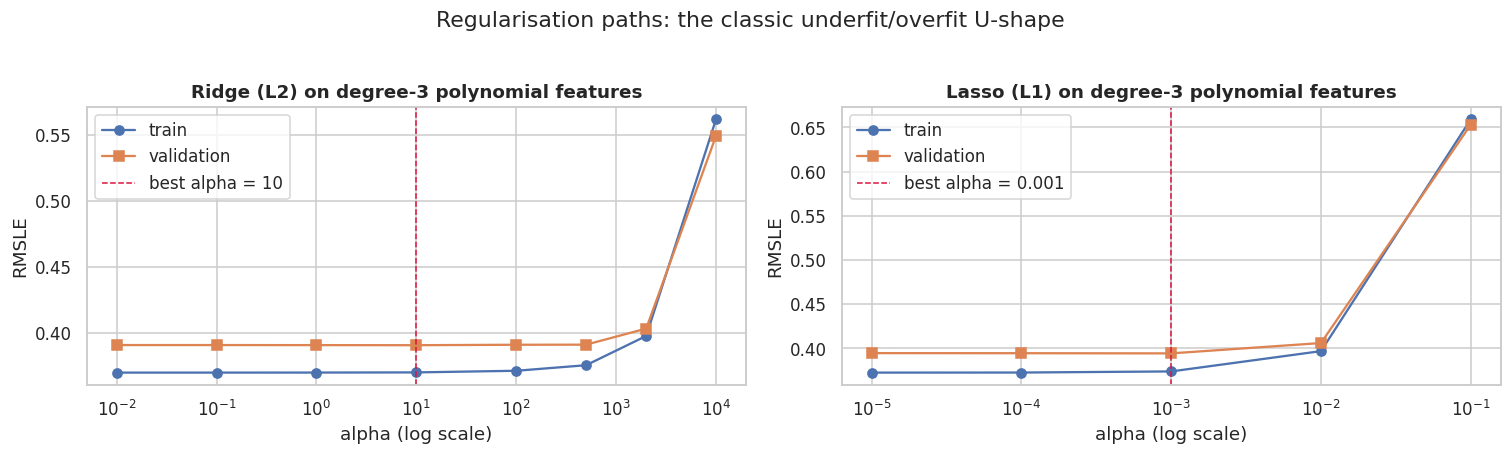

In [ ]:
# ---- Plot the RMSLE vs Alpha values for Ridge and Lasso models ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a_, curve, name, best in [(ax[0], ridge_curve, "Ridge (L2)", best_ridge_alpha),
                              (ax[1], lasso_curve, "Lasso (L1)", best_lasso_alpha)]:
    a_.plot(curve.alpha, curve.train_RMSLE, "o-", label="train")
    a_.plot(curve.alpha, curve.val_RMSLE, "s-", label="validation")
    a_.axvline(best, ls="--", c="crimson", lw=1, label=f"best alpha = {best:g}")
    a_.set_xscale("log"); a_.set_xlabel("alpha (log scale)"); a_.set_ylabel("RMSLE")
    a_.set_title(f"{name} on degree-3 polynomial features"); a_.legend()
plt.suptitle("Regularisation paths: the classic underfit/overfit U-shape", y=1.03)
plt.show()

In [ ]:
# ---- Model 6: Polynomial Regression of Degree 2 ----
register(f"M6  Ridge  (alpha={best_ridge_alpha:g}) | poly degree 3",
         make_pipeline(Ridge(alpha=best_ridge_alpha, random_state=12), num_cols, cat_cols, degree=3), all_cols)

# ---- Model 7: Polynomial Regression of Degree 2 ----
register(f"M7  Lasso  (alpha={best_lasso_alpha:g}) | poly degree 3",
         make_pipeline(Lasso(alpha=best_lasso_alpha, max_iter=20, random_state=12), num_cols, cat_cols, degree=3), all_cols)

M6  Ridge  (alpha=10) | poly degree 3        train=0.3698 val=0.3904  (0.6s)
M7  Lasso  (alpha=0.001) | poly degree 3     train=0.3737 val=0.3942  (0.7s)


np.float64(0.3942)

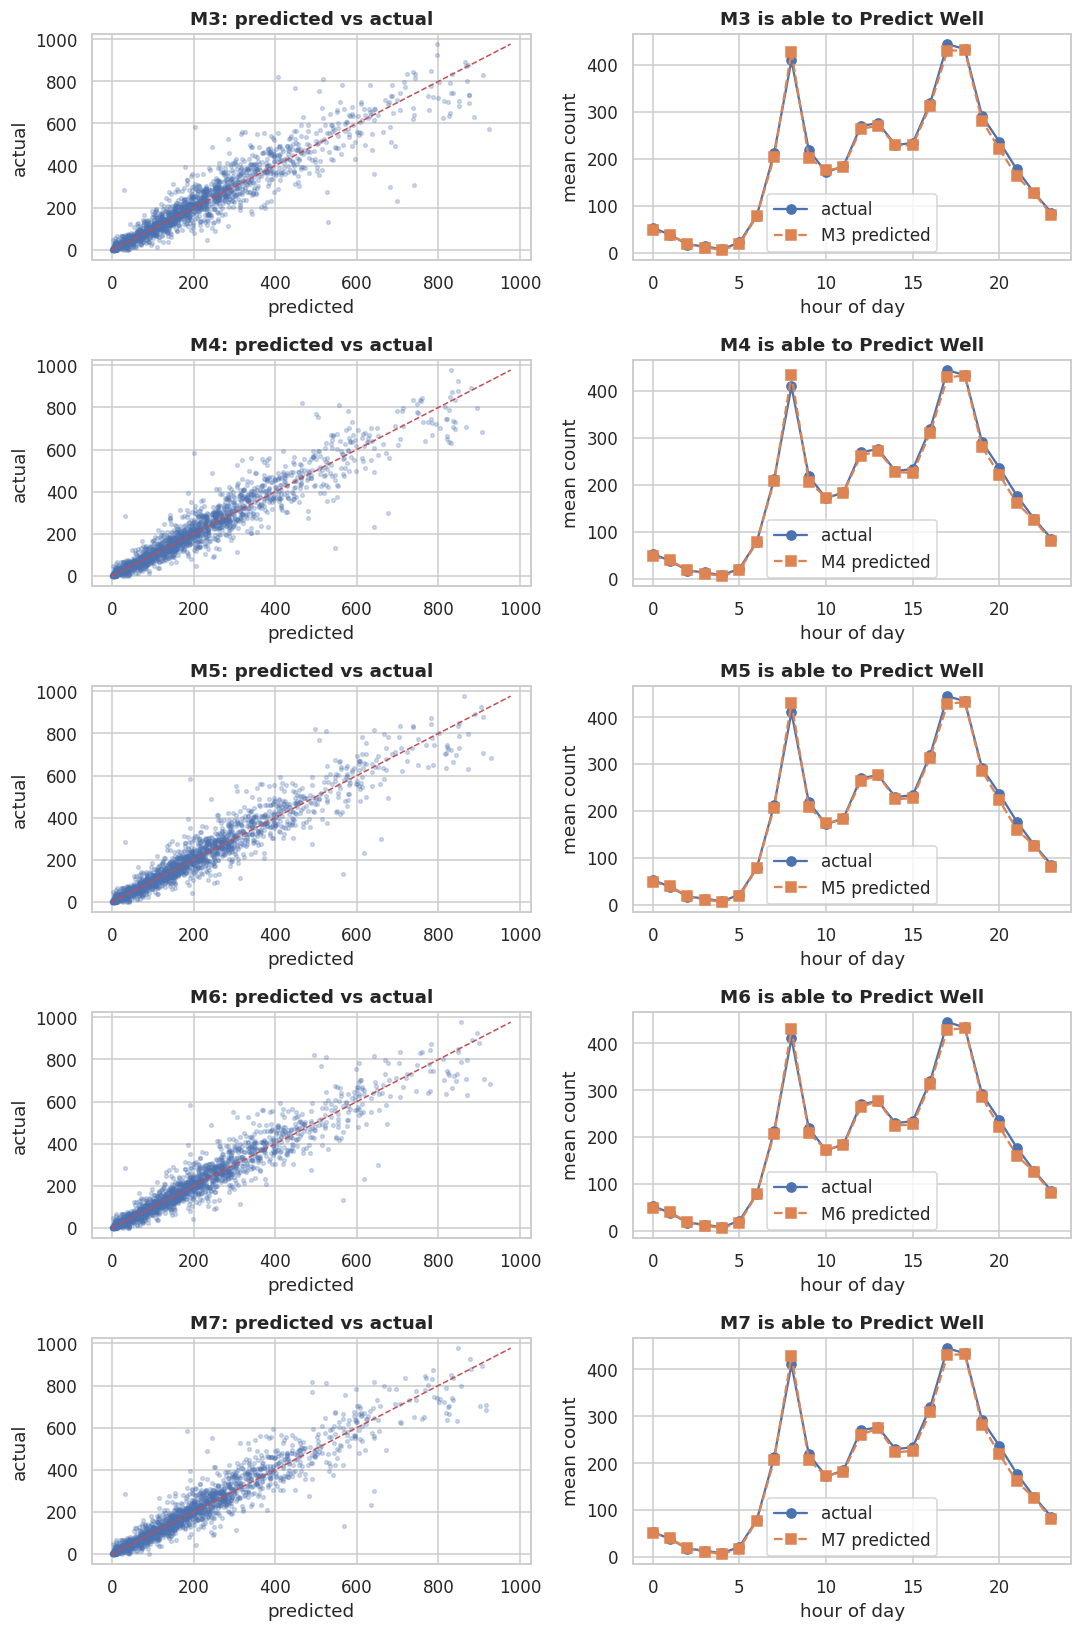

In [ ]:
# ---- Plot the Predictions from the Models M3, M4, M5, M6 and M7 ----

models=['M3  LinearRegression | Time fetaures added under Categorical',
        'M4  LinearRegression | Polynomial degree 2 (numeric)',
        'M5  LinearRegression | Polynomial degree 3 (numeric)',
        'M6  Ridge  (alpha=10) | poly degree 3',
        'M7  Lasso  (alpha=0.001) | poly degree 3']

fig, ax = plt.subplots(5, 2, figsize=(10, 15))

for i in range (0,5):
    m_fit, m_features, _ = FITTED[f"{models[i]}"]
    pred_val_m = np.clip(np.expm1(m_fit.predict(X_val[m_features])), 1, None)

    ax[i,0].scatter(pred_val_m, y_val, s=6, alpha=.25)
    lim = [0, max(y_val.max(), pred_val_m.max())]
    ax[i,0].plot(lim, lim, "r--", lw=1)
    ax[i,0].set_xlabel("predicted"); ax[i,0].set_ylabel("actual"); ax[i,0].set_title(f"M{i+3}: predicted vs actual")
    tmp = pd.DataFrame({"hour": X_val["hour"].values, "actual": y_val, "pred": pred_val_m})
    h = tmp.groupby("hour")[["actual", "pred"]].mean()
    ax[i,1].plot(h.index, h["actual"], "o-", label="actual")
    ax[i,1].plot(h.index, h["pred"], "s--", label=f"M{i+3} predicted")
    ax[i,1].set_xlabel("hour of day"); ax[i,1].set_ylabel("mean count"); ax[i,1].legend()
    ax[i,1].set_title(f"M{i+3} is able to Predict Well")

plt.tight_layout()
plt.show()

**Analysis of the Advanced Regression Models:**

* **Model 3:** We got the best improvement in RMSLE from *1.2222 to 0.4013* just by using the time data in our training. It shows how import the hour and workday are for accurate predictions.

* **Model 4 & 5:**
Expanding the number of numeric features in Degree 2, and then further with Degree 3 resulted in minor improvemenst from the Degree 1 model. The improvements are small and can be said to be nearly negligible.

* **Model 6:** For Ridge, at **α = 10**, we got the best **0.3904**, but it is also just a slight improvement over the accuracy from M5.
* **Model 7:** For Lasso, at **α = e^-5**, we got the best **0.3904**, but it is identical to the accuracy from M6, Ridge model.


## Q7. Model Comparison

In [ ]:
# ---- Create a Table to show the comparison of the 7 Models generated ----
summary = pd.DataFrame(RESULTS)
summary = summary.sort_values("val_RMSLE").reset_index(drop=True)
summary.insert(0, "rank", summary.index + 1)

view = summary[["rank", "model", "target", "n_features_in",
                "train_RMSLE", "val_RMSLE", "val_RMSE", "time_taken"]]

display(view.style.background_gradient(subset=["val_RMSLE"], cmap="RdYlGn_r").format(precision=3))

,rank,model,target,n_features_in,train_RMSLE,val_RMSLE,val_RMSE,time_taken
0,1,M6 Ridge (alpha=10) | poly degree 3,log1p(count),17,0.370,0.390,50.100,0.600
1,2,M5 LinearRegression | Polynomial degree 3 (numeric),log1p(count),17,0.370,0.391,50.100,0.600
2,3,M4 LinearRegression | Polynomial degree 2 (numeric),log1p(count),17,0.376,0.392,51.200,0.600
3,4,M7 Lasso (alpha=0.001) | poly degree 3,log1p(count),17,0.374,0.394,50.400,0.700
4,5,M3 LinearRegression | Time fetaures added under Categorical,log1p(count),17,0.385,0.401,55.800,1.800
5,6,"M2 LinearRegression | raw features, y=log1p",log1p(count),8,1.248,1.222,173.800,0.200
6,7,"M1 LinearRegression | raw features, y=count",count,8,1.442,1.395,156.300,0.100


**Comparison Regression Models:**

* The simple raw-feature linear model is weakest because it cannot represent the strong nonlinear time-of-day pattern. Feature engineering plus log-target modelling substantially improves performance.

* Polynomial Ridge models perform best because polynomial terms capture nonlinear effects and interactions while Ridge regularization limits coefficient instability.

* We have received the best value for RMSLE (0.390) with the Ridge Regression model when the Degree was 3 and alpha=10.

## Q8. Residual Plot

In [ ]:
# ---- Compute the Residual Values for the Best model ----
BEST_Model = "M6  Ridge  (alpha=10) | poly degree 3"
lin_model, lin_feats, lin_log = FITTED[f"{BEST_Model}"]
pred_val = np.clip(np.expm1(lin_model.predict(X_val[lin_feats])), 1, None)

residuals = y_val - pred_val
resid_log = np.log1p(y_val) - np.log1p(pred_val)

print(f"\nbest model: M6  Ridge  (alpha=10) | poly degree 3")
print(f"  validation RMSLE          : {rmsle(y_val, pred_val):.4f}")
print(f"  log-residual mean / sd    : {resid_log.mean():+.4f} / {resid_log.std():.4f}")


best model: M6  Ridge  (alpha=10) | poly degree 3
  validation RMSLE          : 0.3904
  log-residual mean / sd    : +0.0012 / 0.3905


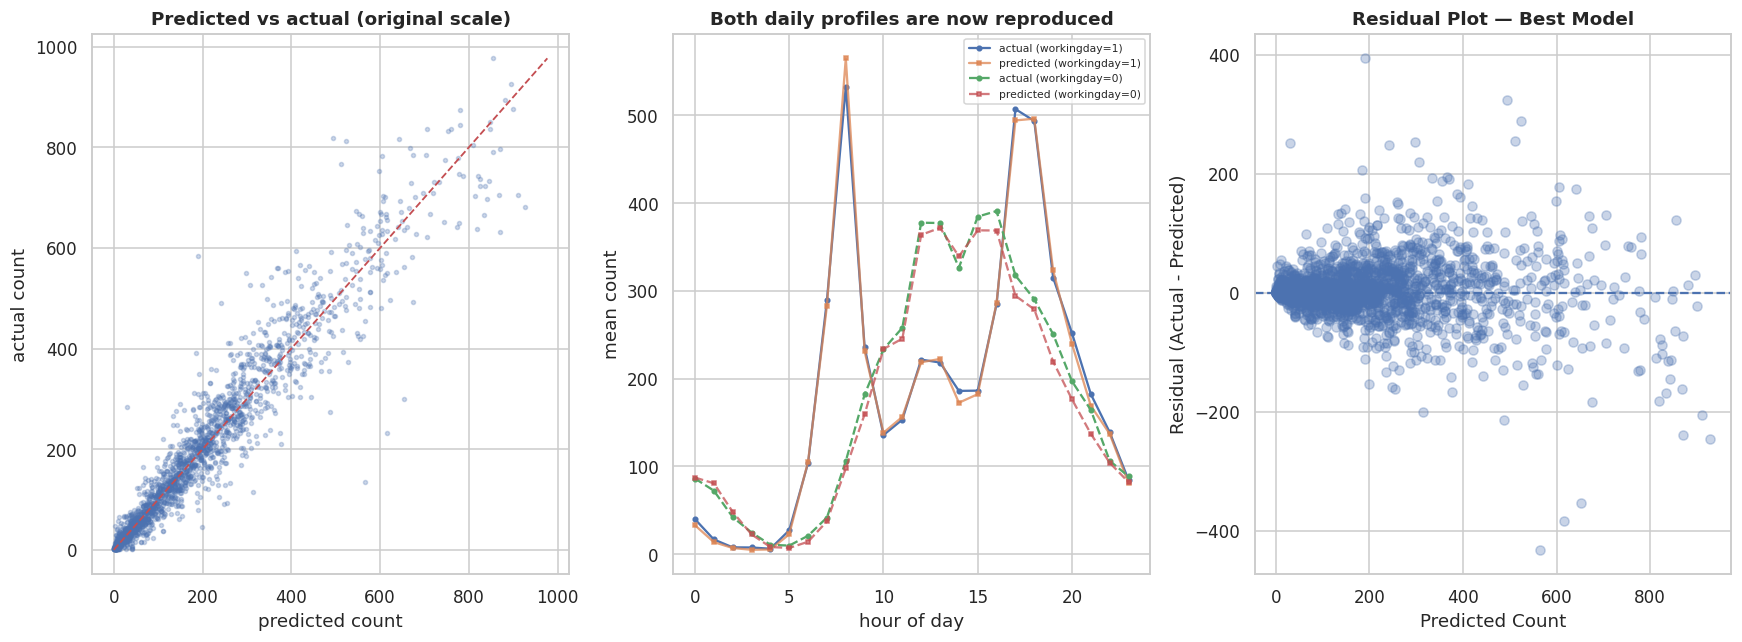

<Figure size 704x528 with 0 Axes>

In [ ]:
# ---- Plot the Residual Values for the Best model ----
rv = pd.DataFrame({"hour": X_val["hour"].values, "workingday": X_val["workingday"].values,
                   "r": resid_log, "actual": y_val, "pred": pred_val})

fig, ax = plt.subplots(1, 3, figsize=(16, 6))

ax[0].scatter(pred_val, y_val, s=7, alpha=.28)
lim = [0, max(y_val.max(), pred_val.max())]
ax[0].plot(lim, lim, "r--", lw=1.2)
ax[0].set_xlabel("predicted count")
ax[0].set_ylabel("actual count")
ax[0].set_title("Predicted vs actual (original scale)")


prof = rv.groupby(["workingday", "hour"])[["actual", "pred"]].mean().reset_index()
for wd, style in [(1, "-"), (0, "--")]:
    s = prof[prof.workingday == wd]
    ax[1].plot(s.hour, s.actual, style, marker="o", ms=3,
                  label=f"actual (workingday={wd})")
    ax[1].plot(s.hour, s.pred, style, marker="s", ms=3, alpha=.75,
                  label=f"predicted (workingday={wd})")
ax[1].set_xlabel("hour of day")
ax[1].set_ylabel("mean count")
ax[1].legend(fontsize=7)
ax[1].set_title("Both daily profiles are now reproduced")


ax[2].scatter(pred_val,residuals,alpha=0.3)
ax[2].axhline(0,linestyle='--')
ax[2].set_xlabel('Predicted Count')
ax[2].set_ylabel('Residual (Actual - Predicted)')
ax[2].set_title('Residual Plot — Best Model')

plt.show()

plt.suptitle(f"Residual diagnostics — {BEST_Model}", y=1.02, fontsize=12)
plt.show()

**Analysis on the Residual plots**
* Residuals are plotted for the best model: **M6  Ridge  (alpha=10) | poly degree 3 0.3904**.

* **Predicted vs actual** clusters along the 45° line. At the top end there is a mild tendency to
  under-predict the most extreme peak hours.
* **The Daily Profile panel** shows both fitted daily profiles — bimodal on working days, single-humped
  on weekends — tracking the actual curves closely. This is direct visual confirmation that the
  `hour × workingday` design did what it was intended to do.

## Q9. Why does the winning model perform better?

The winning model works due to 3 conditions:

1. Datetime is converted into hour, weekday, month, year and interaction categories, so the model can represent different demand regimes rather than forcing one straight-line relationship.
2. Polynomial terms capture nonlinear effects of temperature, humidity, windspeed and calendar variables.
3. Ridge regularization shrinks unstable coefficients introduced by the expanded feature space. Training on log1p(count) also makes the fitted target scale more consistent with RMSLE. Together these choices reduce both underfitting and overfitting.

## Q10. Why does RMSLE penalize under-predictions more gently than RMSE?

* RMSLE is ordinary squared error computed on the `log1p` scale, so it measures
**ratio** error rather than **absolute** error. Because `log1p` compresses large values, a shortfall
on a high-demand hour — which is exactly where the largest absolute errors occur — is squeezed into a
small penalty. And crucially, the penalty RMSLE can charge for an under-prediction is **bounded**,
whereas RMSE's is unbounded.

* RMSLE applies the logarithm before measuring the error, so it focuses more on relative or multiplicative differences than absolute differences. It therefore reduces the influence of very large target values compared with RMSE.
* RMSLE is also approximately symmetric for multiplicative over- and under-predictions, so the statement that it specifically penalizes under-predictions more gently is only applicable in comparison to RMSE.

## Q11. What are the trade-offs between model simplicity and predictive power?

* A simple linear model is easy to interpret, fast to train, and less likely to overfit, but it can underfit complex relationships.
* Polynomial features and engineered interactions increase predictive power by modelling nonlinear patterns, but they create more features, increase computation, and can overfit.
* Ridge/Lasso provide regularization: Ridge stabilizes correlated coefficients, while Lasso can shrink some coefficients toward zero and perform feature selection.
* The goal is therefore not maximum complexity, but the simplest model that gives strong validation performance.

## Q12. Why can’t Linear Regression alone capture time-of-day effects effectively?

* If hour is represented as a single numeric variable, ordinary linear regression assumes that moving from 1 to 2 to 3 to 4 hours changes demand in one approximately constant direction.
* Bike demand does not behave this way: demand can be low at night, rise sharply during morning/evening commuting hours, and fall again later.
* This is a nonlinear and interaction-dependent pattern. One-hot encoding of hour, polynomial/cyclical features, and interactions with workingday/weekday allow the model to represent these distinct hourly demand patterns.

## Final Model and submission.csv

predictions : n=2613  min=1.00  max=925.82  mean=186.51


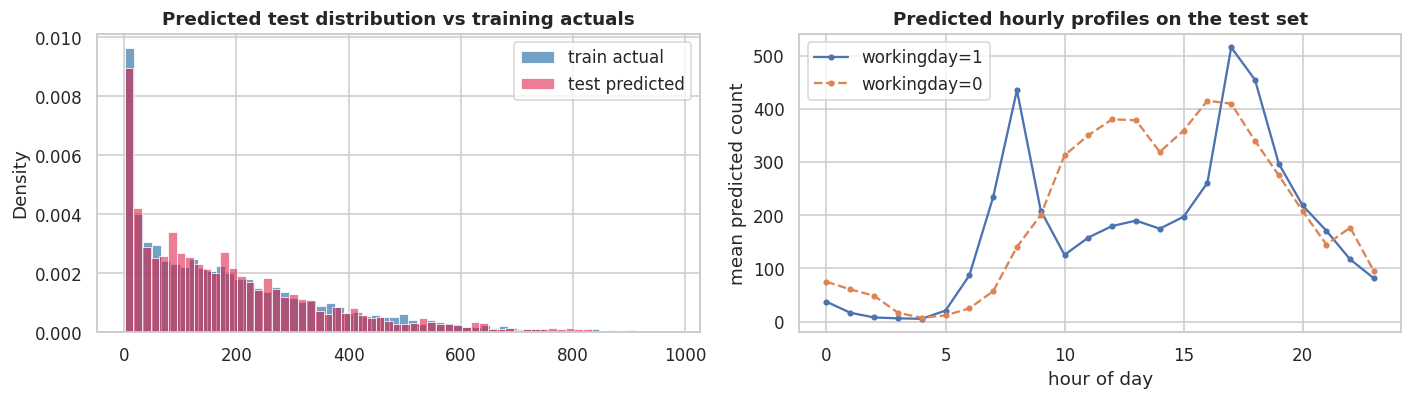

In [ ]:
# ---- Use the Best model to create Predictions on the Submission Dataset----
X_test = make_features(test).drop(columns=['datetime'])
final_model, final_feats, final_log = FITTED[f"{BEST_Model}"]
test_pred = np.clip(np.expm1(lin_model.predict(X_test)), 1, None)

print(f"predictions : n={len(test_pred)}  min={test_pred.min():.2f}  "
      f"max={test_pred.max():.2f}  mean={test_pred.mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(y_full, bins=60, ax=ax[0], color="steelblue", stat="density", label="train actual")
sns.histplot(test_pred, bins=60, ax=ax[0], color="crimson", stat="density", alpha=.55, label="test predicted")
ax[0].legend(); ax[0].set_title("Predicted test distribution vs training actuals")

tp = pd.DataFrame({"hour": X_test["hour"].values,
                   "workingday": X_test["workingday"].values, "pred": test_pred})
for wd, style in [(1, "-"), (0, "--")]:
    s = tp[tp.workingday == wd].groupby("hour")["pred"].mean()
    ax[1].plot(s.index, s.values, style, marker="o", ms=3, label=f"workingday={wd}")
ax[1].set_xlabel("hour of day"); ax[1].set_ylabel("mean predicted count"); ax[1].legend()
ax[1].set_title("Predicted hourly profiles on the test set")
plt.show()

In [ ]:
# ---- Save the predictions to submission.csv file ----
submission = pd.DataFrame({'datetime': test['datetime'].values,'count_predicted': test_pred})
submission.to_csv('submission.csv',index=False)

## Submission Validation

In [ ]:
# ---- Verify the submission.csv file ----
print(submission.head())

print("\nShape:")
print(submission.shape)

print("\nColumns:")
print(submission.columns.tolist())

print("\nMissing values:")
print(submission.isna().sum())

print("\nNegative predictions:")
print((submission['count_predicted'] < 0).sum())

           datetime  count_predicted
0   05-06-2012 5:00        10.600784
1  19-03-2011 19:00       113.435210
2   02-04-2012 6:00        37.271243
3  13-07-2012 20:00       342.691463
4  09-11-2011 19:00       149.910043

Shape:
(2613, 2)

Columns:
['datetime', 'count_predicted']

Missing values:
datetime           0
count_predicted    0
dtype: int64

Negative predictions:
0


In [ ]:
assert submission.shape[0] == test.shape[0]

assert submission.columns.tolist() == [
    'datetime',
    'count_predicted'
]

assert submission['count_predicted'].notna().all()

assert (submission['count_predicted'] >= 0).all()

assert submission['datetime'].equals(
    test['datetime']
)

print("Submission validation passed!")

Submission validation passed!
